# Car Price Analysis and Prediction

An educational case study exploring how vehicle specifications relate to price, followed by a comparison of regression models.

**Business question:** Which vehicle characteristics are associated with price, and how accurately can a model estimate price within this sample?

**Data:** 205 cars; 164 training records and 41 held-out test records. Run this notebook from the repository folder after installing `requirements.txt`.

This work was developed during Data Science training at Entri. EDA uses training data; preprocessing is fitted within model pipelines. See the README for findings, recorded results, and limitations.


In [61]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load and inspect the dataset

In [62]:
df = pd.read_csv("CarPrice_Assignment.csv")
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [63]:
print("Dataset Shape:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\n Data information:")
df.info()
print("\n missing values:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

Dataset Shape: (205, 26)

Column names:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

 Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation 

## 2. Standardize brands and prepare features

In [64]:
df_clean = df.copy()
df_clean["brand"]=(df_clean["CarName"].str.strip().str.lower().str.split().str[0])
print("Brands before correction:")
print(sorted(df_clean["brand"].unique()))

Brands before correction:
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']


In [65]:
brand_corrections ={
    "alfa-romero": "alfa-romeo",
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen"
}
df_clean["brand"]=df_clean["brand"].replace(brand_corrections)
print("Brands after correction:")
print(sorted(df_clean["brand"].unique()))
print("\nNumber of brands:", df_clean["brand"].nunique())

Brands after correction:
['alfa-romeo', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']

Number of brands: 22


In [66]:
df_clean= df_clean.drop(columns=["car_ID","CarName"], axis=1)
print("Cleaned dataset shape:",df_clean.shape)
df_clean.head()

Cleaned dataset shape: (205, 25)


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romeo
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romeo
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romeo
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


## 3. Separate the target and reserve test data

In [67]:
X = df_clean.drop(columns=["price"])
y = df_clean["price"]
print("feature shape:", X.shape)
print("target shape:", y.shape)

feature shape: (205, 24)
target shape: (205,)


In [68]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.20,random_state=42)
print("X_train shape:",X_train.shape)
print("X_test shape:",X_test.shape)
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)

X_train shape: (164, 24)
X_test shape: (41, 24)
y_train shape: (164,)
y_test shape: (41,)


In [69]:


numerical_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical features:")
print(numerical_features)
print("Numerical feature count:", len(numerical_features))

print("\nCategorical features:")
print(categorical_features)
print("Categorical feature count:", len(categorical_features))

Numerical features:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Numerical feature count: 14

Categorical features:
['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Categorical feature count: 10


## 4. Explore the training data

In [70]:
train_df = X_train.copy()
train_df["price"]=y_train
print("Training dataset shape:",train_df.shape)
train_df.head()

Training dataset shape: (164, 25)


,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,brand,price
66,0,diesel,std,four,sedan,rwd,front,104.9,175.0,66.1,...,idi,3.43,3.64,22.0,72,4200,31,39,mazda,18344.0
111,0,gas,std,four,sedan,rwd,front,107.9,186.7,68.4,...,mpfi,3.46,2.19,8.4,95,5000,19,24,peugeot,15580.0
153,0,gas,std,four,wagon,fwd,front,95.7,169.7,63.6,...,2bbl,3.05,3.03,9.0,62,4800,31,37,toyota,6918.0
96,1,gas,std,four,sedan,fwd,front,94.5,165.3,63.8,...,2bbl,3.15,3.29,9.4,69,5200,31,37,nissan,7499.0
38,0,gas,std,two,hatchback,fwd,front,96.5,167.5,65.2,...,1bbl,3.15,3.58,9.0,86,5800,27,33,honda,9095.0


In [71]:
summary = train_df.describe()

summary.T

,count,mean,std,min,25%,50%,75%,max
symboling,164.0,0.902439,1.244470,-2.00,0.000,1.00,2.000,3.00
wheelbase,164.0,98.728659,5.968884,86.60,94.500,96.75,102.100,115.60
carlength,164.0,174.127439,12.080544,144.60,166.675,173.10,183.200,202.60
carwidth,164.0,65.922561,2.123469,61.80,64.175,65.50,66.675,72.30
carheight,164.0,53.715854,2.479386,47.80,51.900,54.10,55.525,59.80
curbweight,164.0,2556.439024,511.935461,1819.00,2163.000,2422.50,2939.250,4066.00
enginesize,164.0,126.414634,40.469014,70.00,98.000,119.50,141.000,326.00
boreratio,164.0,3.320854,0.269766,2.54,3.150,3.31,3.540,3.94
stroke,164.0,3.254909,0.317892,2.07,3.110,3.28,3.410,4.17
compressionratio,164.0,10.089085,3.854172,7.00,8.600,9.00,9.400,23.00


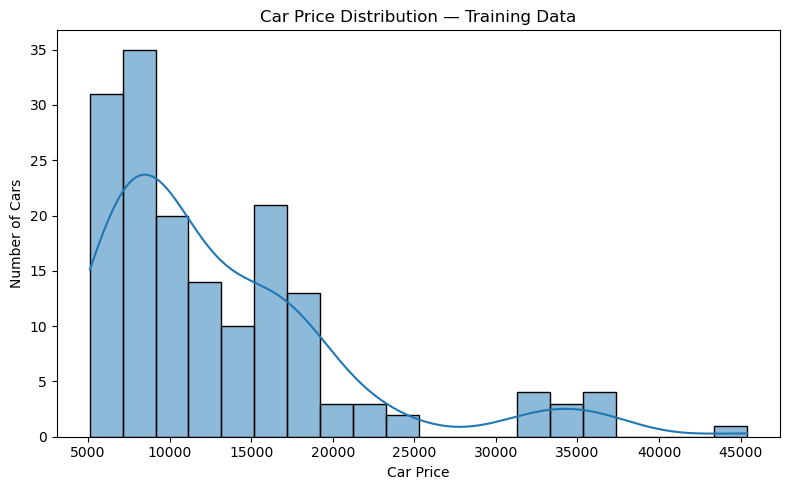

In [72]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_df,
    x="price",
    bins=20,
    kde=True
)

plt.title("Car Price Distribution — Training Data")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

The training car-price distribution is right-skewed. Most cars are priced between approximately 5,000 and 20,000, with fewer observations at higher prices. High-price observations are retained because a high price alone does not indicate a data error.

In [73]:
correlation_matrix = train_df.select_dtypes(
    include="number"
).corr()

price_correlations = correlation_matrix["price"].drop(
    labels=["price"]
)

price_correlations = price_correlations.sort_values(
    ascending=False
)

print(price_correlations.round(3))

enginesize          0.866
curbweight          0.824
horsepower          0.811
carwidth            0.744
carlength           0.652
boreratio           0.546
wheelbase           0.506
carheight           0.044
compressionratio    0.035
stroke              0.024
symboling          -0.005
peakrpm            -0.070
citympg            -0.711
highwaympg         -0.714
Name: price, dtype: float64


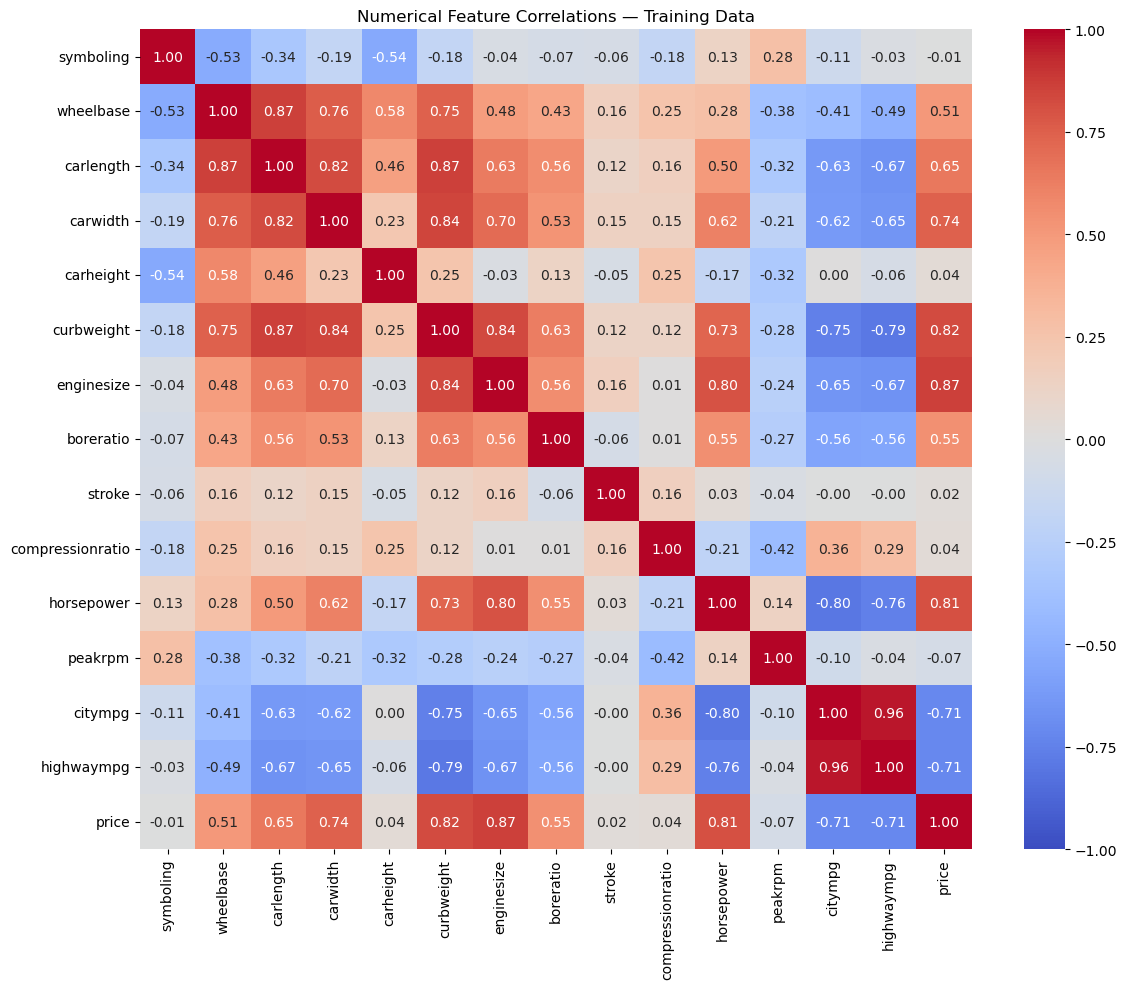

In [74]:
plt.figure(figsize=(12, 10))

sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1)
plt.title("Numerical Feature Correlations — Training Data")

plt.tight_layout()
plt.show()

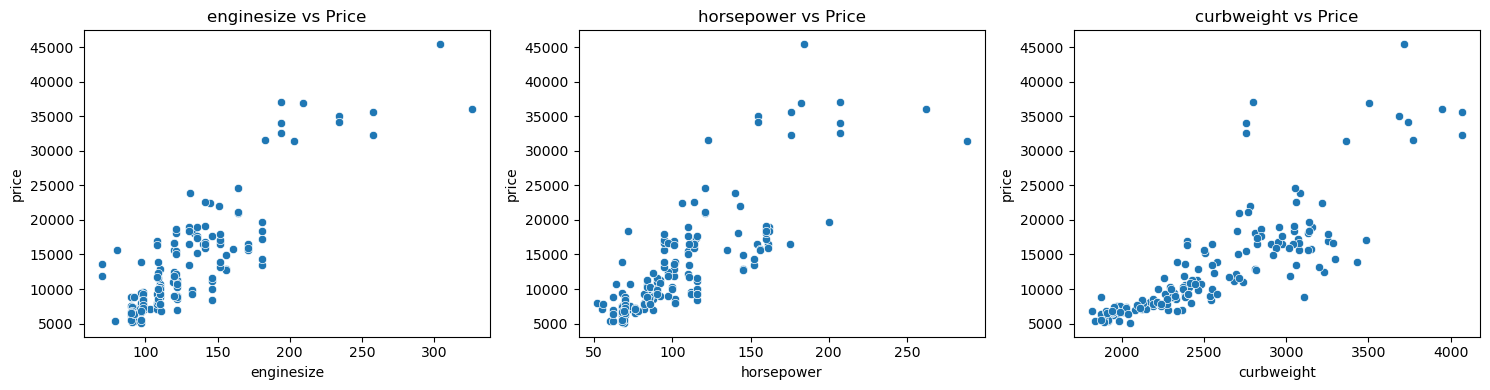

In [75]:
features_to_plot = ["enginesize", "horsepower", "curbweight"]

plt.figure(figsize=(15, 4))

for position, feature in enumerate(features_to_plot, start=1):
    plt.subplot(1, 3, position)

    sns.scatterplot(
        data=train_df,
        x=feature,
        y="price"
    )

    plt.title(f"{feature} vs Price")

plt.tight_layout()
plt.show()

In [76]:
print("car_ID in X:", "car_ID" in X.columns)
print("CarName in X:", "CarName" in X.columns)
print("brand in X:", "brand" in X.columns)
print("car_ID in train_df:", "car_ID" in train_df.columns)
print("X shape:", X.shape)


car_ID in X: False
CarName in X: False
brand in X: True
car_ID in train_df: False
X shape: (205, 24)


In [77]:
categories_to_analyze = ["brand", "carbody", "fueltype"]

for column in categories_to_analyze:
    print(f"\nCar counts by {column}:")
    print(train_df[column].value_counts())


Car counts by brand:
brand
toyota        25
mazda         14
nissan        13
honda         12
peugeot       11
volkswagen    10
mitsubishi     9
subaru         8
dodge          8
volvo          8
audi           6
bmw            6
plymouth       6
saab           5
porsche        5
buick          4
jaguar         3
alfa-romeo     3
isuzu          3
renault        2
chevrolet      2
mercury        1
Name: count, dtype: int64

Car counts by carbody:
carbody
sedan          78
hatchback      56
wagon          19
convertible     6
hardtop         5
Name: count, dtype: int64

Car counts by fueltype:
fueltype
gas       149
diesel     15
Name: count, dtype: int64


In [78]:
for column in categories_to_analyze:
    price_summary = (
        train_df.groupby(column)["price"]
        .agg(["count", "mean", "median"])
        .sort_values(by="median", ascending=False)
    )

    print(f"\nPrice summary by {column}:")
    print(price_summary.round(2))


Price summary by brand:
            count      mean   median
brand                               
jaguar          3  34600.00  35550.0
buick           4  36560.00  34620.0
porsche         5  31400.50  32528.0
bmw             6  22812.50  21037.5
volvo           8  18856.88  18685.0
audi            6  17859.17  17580.0
peugeot        11  15489.09  16630.0
mercury         1  16503.00  16503.0
alfa-romeo      3  15498.33  16500.0
saab            5  15898.00  15510.0
mazda          14  10241.36  10420.0
volkswagen     10   9986.00   9737.5
renault         2   9595.00   9595.0
toyota         25  10281.96   9298.0
isuzu           3   8916.50   8916.5
mitsubishi      9   8569.00   8499.0
dodge           8   8023.38   7783.0
plymouth        6   8252.50   7783.0
subaru          8   7951.88   7689.0
honda          12   8326.83   7595.0
nissan         13  10799.00   7499.0
chevrolet       2   6435.00   6435.0

Price summary by carbody:
             count      mean   median
carbody               

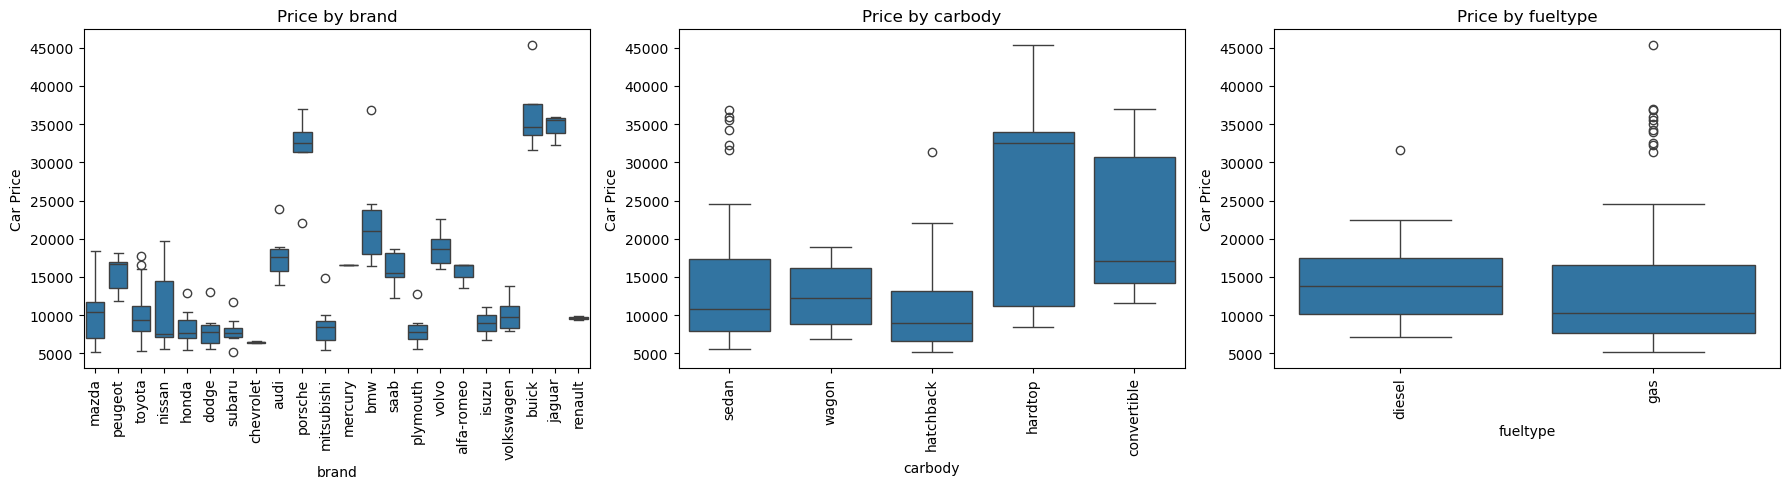

In [79]:
plt.figure(figsize=(18, 5))

for position, column in enumerate(categories_to_analyze, start=1):
    plt.subplot(1, 3, position)

    sns.boxplot(
        data=train_df,
        x=column,
        y="price"
    )

    plt.title(f"Price by {column}")
    plt.xlabel(column)
    plt.ylabel("Car Price")
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Car prices vary across brands, body types, and fuel types in the training sample. Jaguar, Buick, and Porsche have relatively high median prices. Hardtop cars have the highest median among body types, while diesel cars have a higher median than gas cars. These comparisons require caution because category sizes differ and some categories contain very few observations. They describe associations rather than independent causal effects.

## 5. Build preprocessing pipelines

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

In [81]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing configurations are ready.")

Preprocessing configurations are ready.


## 6. Compare regression models using cross-validation

In [82]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate

In [83]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(
        kernel="rbf",
        C=10000,
        epsilon=100
    )
}

print("Number of models:", len(models))

Number of models: 5


In [84]:
model_pipelines = {}

for name, model in models.items():
    if name in ["Linear Regression", "SVR"]:
        preprocessor = scaled_preprocessor
    else:
        preprocessor = tree_preprocessor

    model_pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ]
    )

print("Pipelines created:", list(model_pipelines.keys()))

Pipelines created: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVR']


In [85]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "r2": "r2",
    "mse": "neg_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

In [86]:
results = []

for name, pipeline in model_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "CV R²": scores["test_r2"].mean(),
        "CV MSE": -scores["test_mse"].mean(),
        "CV MAE": -scores["test_mae"].mean()
    })

In [87]:
cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by="CV R²",
    ascending=False
).reset_index(drop=True)

cv_results.round(3)

,Model,CV R²,CV MSE,CV MAE
0,Random Forest,0.890,6.513629e+06,1729.955
1,Gradient Boosting,0.887,6.734152e+06,1726.884
2,SVR,0.870,7.866616e+06,1926.158
3,Linear Regression,0.864,7.867208e+06,1840.507
4,Decision Tree,0.819,1.041658e+07,2135.314


## 7. Tune Random Forest on training data

In [88]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2]
}

In [89]:
grid_search = GridSearchCV(
    estimator=model_pipelines["Random Forest"],
    param_grid=param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,'raise'
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [90]:
baseline_r2 = cv_results.loc[
    cv_results["Model"] == "Random Forest", "CV R²"
].iloc[0]

print("Best parameters:", grid_search.best_params_)
print("Before tuning CV R²:", round(baseline_r2, 4))
print("After tuning CV R²:", round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Before tuning CV R²: 0.8899
After tuning CV R²: 0.8924


## 8. Evaluate on the held-out test set

In [92]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
test_results = []

for name, pipeline in model_pipelines.items():
    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_train, y_train)

    predictions = fitted_pipeline.predict(X_test)

    test_results.append({
        "Model": name,
        "Test R²": r2_score(y_test, predictions),
        "Test MSE": mean_squared_error(y_test, predictions),
        "Test MAE": mean_absolute_error(y_test, predictions)
    })

tuned_predictions = best_model.predict(X_test)

test_results.append({
    "Model": "Tuned Random Forest",
    "Test R²": r2_score(y_test, tuned_predictions),
    "Test MSE": mean_squared_error(y_test, tuned_predictions),
    "Test MAE": mean_absolute_error(y_test, tuned_predictions)
})

In [93]:
test_comparison = pd.DataFrame(test_results)

test_comparison = test_comparison.sort_values(
    by="Test R²",
    ascending=False
).reset_index(drop=True)

test_comparison.round(3)

,Model,Test R²,Test MSE,Test MAE
0,Tuned Random Forest,0.959,3233542.350,1259.545
1,Random Forest,0.957,3416471.336,1309.480
2,Gradient Boosting,0.928,5684860.239,1666.640
3,Decision Tree,0.906,7406866.582,1787.654
4,Linear Regression,0.901,7808716.036,1807.704
5,SVR,0.895,8295325.092,1889.322


## 9. Interpret predictive feature importance

In [94]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42
)

In [95]:
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance.round(4)

,Feature,Importance,Std
0,enginesize,0.8214,0.1335
1,curbweight,0.1288,0.0213
2,highwaympg,0.0080,0.0037
3,horsepower,0.0056,0.0028
4,carwidth,0.0043,0.0026
5,compressionratio,0.0032,0.0022
6,citympg,0.0027,0.0022
7,brand,0.0019,0.0009
8,carlength,0.0019,0.0008
9,stroke,0.0018,0.0007


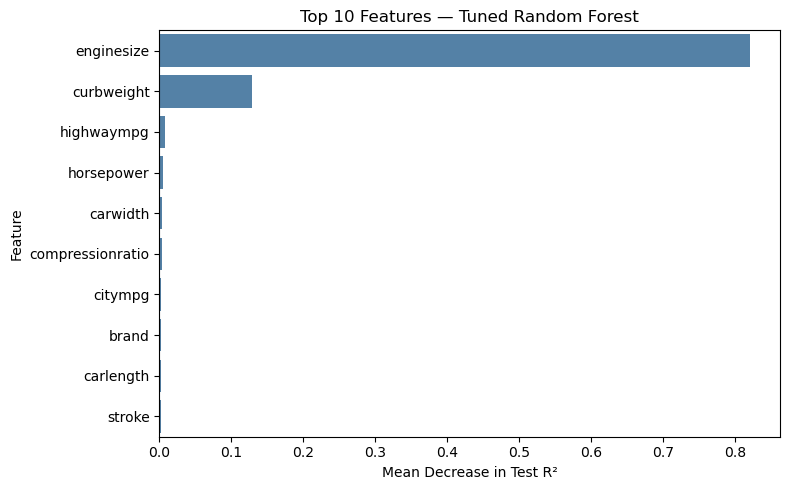

In [96]:
top_features = feature_importance.head(10)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Features — Tuned Random Forest")
plt.xlabel("Mean Decrease in Test R²")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Final Conclusion

Five regression models were implemented and compared using R², MSE,
and MAE. Random Forest achieved the highest mean cross-validation R²
among the initial models and was selected for hyperparameter tuning.

GridSearchCV selected 200 trees, a maximum depth of 10, and a minimum
of 1 sample per leaf. Mean cross-validation R² increased from 0.8899
to 0.8924.

The tuned Random Forest also performed best on the reserved test set:

- R²: approximately 0.959
- MSE: 3,233,542.350
- MAE: 1,259.545

Compared with the original Random Forest, tuning improved all three
test metrics. The tuned model explained approximately 95.9% of the
price variation in this test set.

Permutation importance identified engine size and curb weight as the
most influential predictive features for the fitted model. Highway
MPG, horsepower, and car width showed smaller additional contributions.
These importance values describe predictive usefulness, not statistical
significance or causal effects.

Management can use these findings to understand associations between
vehicle specifications and prices. Results are based on a small dataset
of 205 cars, with 41 cars reserved for testing, and should be validated
on additional representative data before making pricing decisions.